# MFC 센터 레이아웃 · 상대 격자 초안

현재 **A 냉동 / B 냉장 / C 상온 히트맵 / D 상온 랜덤** 기준의 레이아웃 표현입니다.
**5절에서 2026년 9월 출고의 로케이션 코드를 참고해 렉 단위 스케일 지도를 생성합니다.**
출고량 히트맵·동선 계산은 포함하지 않습니다.

전체 구조 사진의 렉 배치 영역과 기둥을 사람이 상대 격자로 옮긴 **개략 초안**입니다.
사진에서 복도·렉 번호를 정확히 판독할 수 없어 번호를 임의로 만들지 않았습니다.
상온은 추가 사진을 반영해 **왼쪽 C 히트맵과 오른쪽 뒤로 길게 이어지는 D 랜덤 구역**을
하나의 `C_D` 도면에 담습니다. 히트맵 상세 정보는 레이아웃 확정 후 제공받기로 했으므로,
현재 상온 렉은 같은 색으로 표시합니다. 기존 사진의 C·D 표기는 배열에 보존합니다.

- 첫 그림: 사용자 설명에 따른 **D → C → 패킹 → B → A** 관계도. 실제 축척·방향은 아닙니다.
- 두 번째 그림: 사진에서 옮긴 **구역별 독립 격자**. 구역 간 위치·통로 연결은 포함하지 않습니다.
- 1~4절은 기존 배치 초안입니다. **5절의 알파벳 칸 하나는 관측된 렉 코드 하나**입니다.
  칸 너비는 기존 렉 영역을 나눈 상대 크기이며 공통 1m 단위가 아닙니다.
- 렉 번호가 확인되면 `RACK_LABELS`에 **존·복도·렉**만 입력합니다. 층·선반은 사용하지 않습니다.
- `.`로 표시한 흰색 칸은 이동 가능한 통로·교차로입니다. `#`은 통행을 막는 기둥입니다.

[운영 context](../docs/mfc_operating_context.md) ·
[전체 구조 사진](../docs/assets/mfc_layout/overall_layout_2026-10-14.png)
[상온 전체 사진](../docs/assets/mfc_layout/ambient_full_2026-10-15.png)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle

from hit_stocks_analysis import find_project_root

ROOT = find_project_root()
OUTPUT = ROOT / "reports/mfc_layout"
OUTPUT.mkdir(parents=True, exist_ok=True)
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "#f8fafc"

ZONES = {
    "A": {"name": "냉동", "color": "#93c5fd"},
    "B": {"name": "냉장", "color": "#fda4af"},
    "C": {"name": "상온 히트맵", "color": "#86efac"},
    "D": {"name": "상온 랜덤", "color": "#fde68a"},
}

## 1. 전체 구역 관계를 배열로 표현

패킹 구역에서 상온 쪽을 보면 가까운 C 히트맵 뒤로 D 랜덤 진열 공간이 길게 이어집니다.
그 관계를 **D → C → 패킹 → B → A**로 표시합니다.
이 배열은 구역의 관계를 나타내며 실제 방향·면적 비율·통행 가능한 셀 지도는 아닙니다.

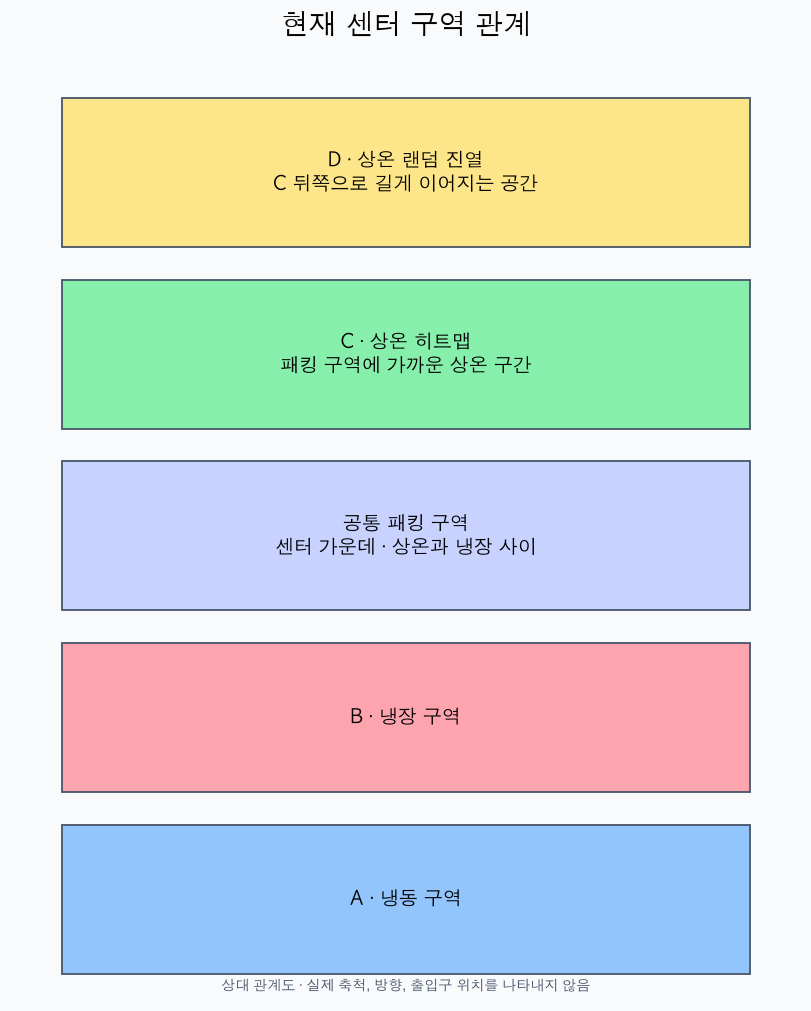

In [2]:
zone_order = np.array(["D", "C", "PACK", "B", "A"])
zone_text = {
    "D": "D · 상온 랜덤 진열\nC 뒤쪽으로 길게 이어지는 공간",
    "C": "C · 상온 히트맵\n패킹 구역에 가까운 상온 구간",
    "PACK": "공통 패킹 구역\n센터 가운데 · 상온과 냉장 사이",
    "B": "B · 냉장 구역",
    "A": "A · 냉동 구역",
}
zone_colors = {zone: info["color"] for zone, info in ZONES.items()}
zone_colors["PACK"] = "#c7d2fe"
fig, ax = plt.subplots(figsize=(8, 10), layout="constrained")
for row, zone in enumerate(zone_order):
    y = len(zone_order) - 1 - row
    ax.add_patch(Rectangle((0, y), 4, 0.82, facecolor=zone_colors[zone],
                           edgecolor="#475569", linewidth=1.3))
    ax.text(2, y + 0.41, zone_text[zone], ha="center", va="center", fontsize=14)
ax.set(xlim=(-0.3, 4.3), ylim=(-0.15, len(zone_order) + 0.05))
ax.axis("off")
ax.set_title("현재 센터 구역 관계", fontsize=20, pad=16)
fig.text(0.5, 0.015, "상대 관계도 · 실제 축척, 방향, 출입구 위치를 나타내지 않음",
         ha="center", fontsize=10, color="#475569")
fig.savefig(OUTPUT / "zone_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. 사진 기반 렉 배치 영역 배열

`src/hit_stocks_analysis/mfc_layout.py`의 `GRID_TEXT`에서 문자를 수정하면 다음 그림이 바뀝니다.
다른 노트북과 같은 원본을 쓰기 위해 격자를 모듈로 옮겼습니다. 같은 도면의 모든 행은 길이가 같아야 합니다.

| 기호 | 의미 |
|---|---|
| `A` | 냉동 A 존의 렉 배치 영역 |
| `B` | 냉장 B 존의 렉 배치 영역 |
| `R` | 상온의 C·D 미지정 렉 배치 영역 |
| `C` | 상온 C 히트맵의 렉 배치 영역 |
| `D` | 상온 D 랜덤 진열의 렉 배치 영역 |
| `#` | 기둥 · 통행 불가 |
| `.` | 이동 가능한 통로·교차로 |
| `?` | 도면 범위 밖 / 미확인 |
| `U` | 사진에서 용도를 판독하지 못한 별도 영역 |

A·B는 기존 전체 사진, 상온 `C_D`는 **2026-10-15 추가 상온 사진**을 기준으로 옮겼습니다.
추가 사진의 초록 음영은 C, 오른쪽 음영 없는 렉은 D라는 사용자 확인을 반영했습니다.
오른쪽 아래의 굽은 외곽은 계단 모양 격자로 근사했습니다. 외곽 바깥 사선 무늬는 진열 공간에
포함하지 않았으며 용도는 확정하지 않습니다. 개별 복도·렉 번호는 여전히 미확인입니다.
옛 I·W·A 개략도의 번호는 치환하지 않았습니다.

사용자 확인에 따라 기존 폭 X=0~33을 유지하고 Y=28·29에 X=27까지 렉을 추가했습니다.
추가 렉은 바로 위 블록의 X=3~8, 11~14, 19~23, 26~27 구간을 이어받습니다.
그 사이 세로 빈 공간을 유지하고, Y=27의 가로 교차 통로를 X=27까지 연장했습니다.
추가 렉의 존은 임의로 지정하지 않고 `R`로 표시합니다.

In [3]:
from hit_stocks_analysis.mfc_layout import GRID_TEXT, parse_grids

# 격자 원본은 src/hit_stocks_analysis/mfc_layout.py의 GRID_TEXT에 있습니다.
layout_arrays = parse_grids(GRID_TEXT)
print({area: grid.shape for area, grid in layout_arrays.items()})

# 사용자 확인: .만 통로이며, #은 통행을 막는 기둥입니다.
walkable_masks = {area: grid == "." for area, grid in layout_arrays.items()}

{'A': (32, 18), 'B': (26, 18), 'C_D': (27, 34)}


## 3. 확인된 존·복도·렉 번호 연결

`RACK_LABELS`는 각 도면의 `(행, 열)`에 표시할 **확인된 렉 코드**를 담습니다.
현재 사진의 개별 번호는 미확인이므로 비워 둡니다. 이 상태에서도 레이아웃 그림은 생성됩니다.

입력 형식은 `{(행, 열): "A01-01"}`입니다. 좌표는 0부터 시작하며 렉 영역 `A`·`B`·`C`·`D`·`R` 위를 지정합니다.
표시 좌표는 렉 영역 안의 라벨 위치이고, 작업자가 서는 피킹 좌표가 아닙니다.
`C_D` 도면에는 확인된 C 또는 D 코드를 넣습니다. 원본의 층·선반 접미사는 넣지 않습니다.

In [4]:
RACK_LABELS = {"A": {}, "B": {}, "C_D": {}}

# 확인된 항목만 [존, 복도, 렉, 도면, 행, 열] 형태의 2차원 배열로 생성합니다.
location_rows = []
for area, labels in RACK_LABELS.items():
    for (row, col), rack_code in labels.items():
        zone_aisle, rack = rack_code.split("-")
        zone, aisle = zone_aisle[0], zone_aisle[1:]
        assert zone in ({"C", "D"} if area == "C_D" else {area})
        assert len(aisle) == len(rack) == 2 and aisle.isdigit() and rack.isdigit()
        grid = layout_arrays[area]
        assert 0 <= row < grid.shape[0] and 0 <= col < grid.shape[1]
        expected_cells = {zone, "R"} if area == "C_D" else {zone}
        assert grid[row, col] in expected_cells, "라벨의 존과 렉 영역을 맞추세요."
        location_rows.append([zone, aisle, rack, area, row, col])
rack_positions = np.array(location_rows, dtype=object).reshape(-1, 6)
print(f"번호가 확인된 렉: {len(rack_positions)}개 (0이면 번호 미입력 상태)")

번호가 확인된 렉: 0개 (0이면 번호 미입력 상태)


## 4. 격자 그림 표시·저장

행 좌표는 위에서 아래로, 열 좌표는 왼쪽에서 오른쪽으로 증가합니다.
세 패널은 각각 독립 좌표이며 패널 사이를 이동할 수 있다는 뜻이 아닙니다.
격자 크기는 현재 `GRID_TEXT`의 행·열 수를 따릅니다. 상온 렉의 히트맵 색상은 보류합니다.
이 격자 크기는 표현을 위한 근사이며 구역 간 실제 크기 비율을 뜻하지 않습니다.
전체 배치도 외에 상온만 크게 보는 `ambient_layout.png`도 저장합니다.

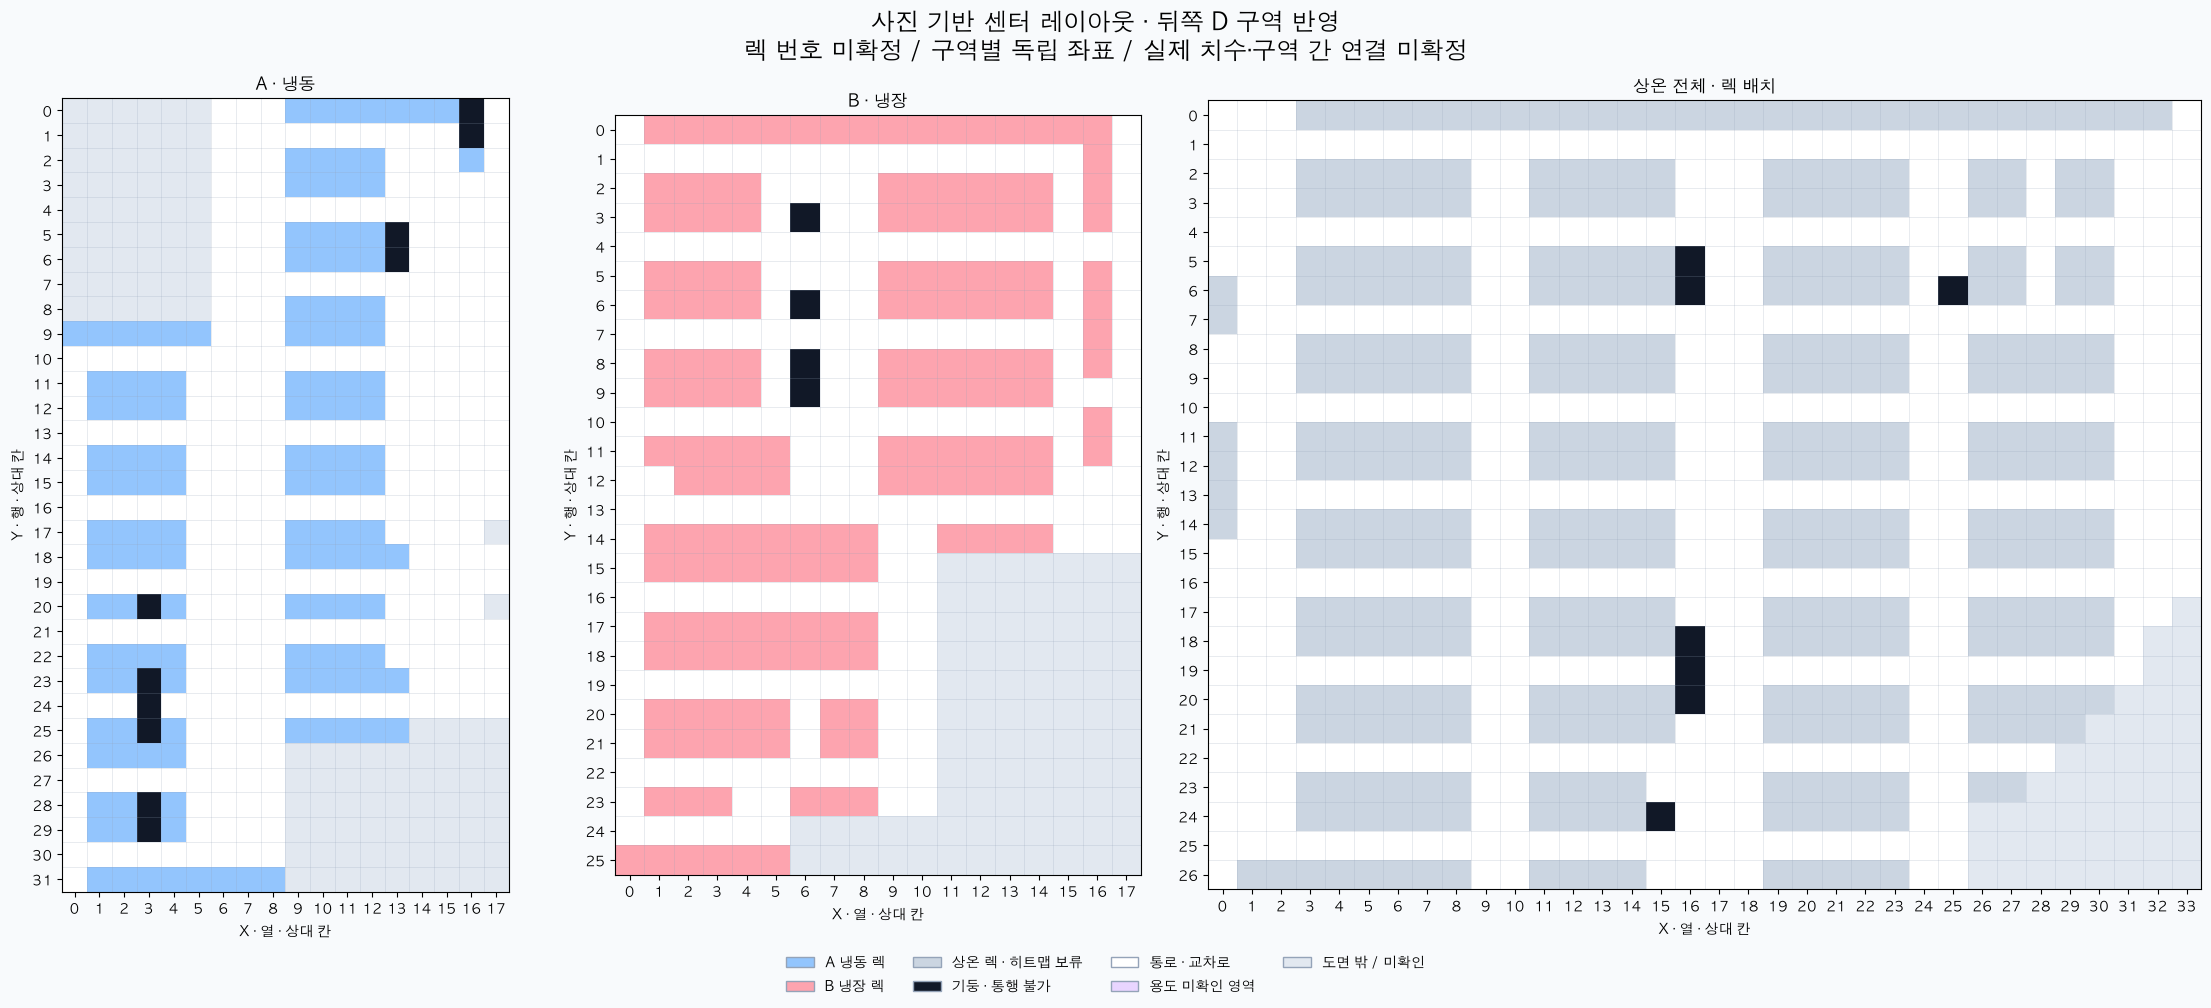

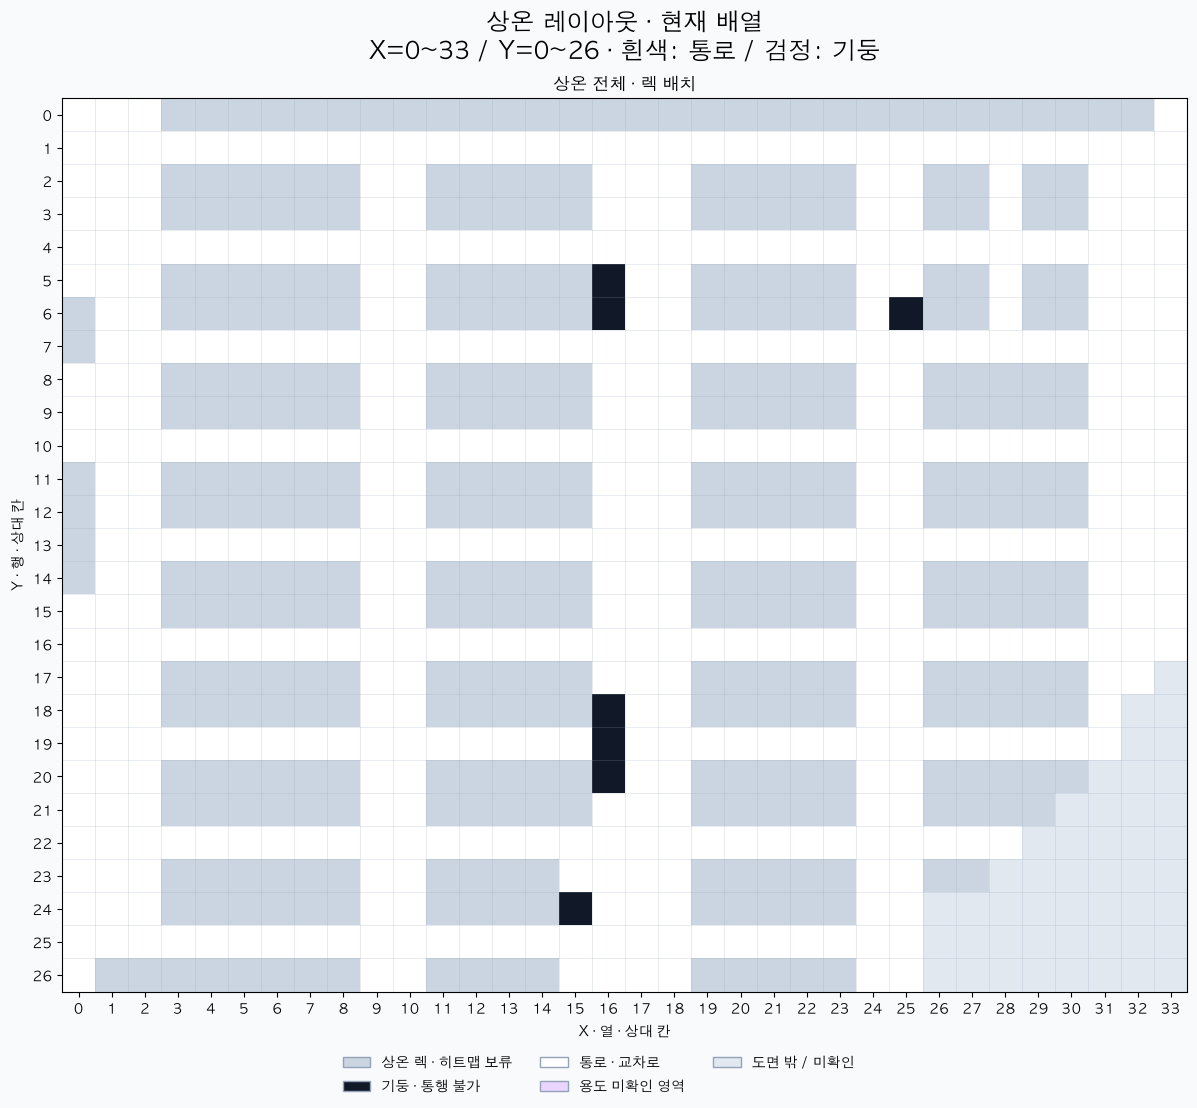

그림 저장: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/mfc_layout


In [5]:
symbols = ["?", ".", "R", "#", "U", "C", "D", "A", "B"]
titles = {"A": "A · 냉동", "B": "B · 냉장", "C_D": "상온 전체 · 렉 배치"}


def draw_layout(ax, area):
    grid = layout_arrays[area]
    rack_color = ZONES[area]["color"] if area in ZONES else "#cbd5e1"
    colors = ["#e2e8f0", "#ffffff", rack_color, "#111827", "#e9d5ff",
              rack_color, rack_color, ZONES["A"]["color"], ZONES["B"]["color"]]
    values = np.zeros(grid.shape, dtype=int)
    for value, symbol in enumerate(symbols):
        values[grid == symbol] = value
    ax.imshow(values, cmap=ListedColormap(colors),
              norm=BoundaryNorm(np.arange(-0.5, len(symbols), 1), len(symbols)),
              interpolation="nearest")
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.set_xticks(np.arange(-0.5, grid.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, grid.shape[0], 1), minor=True)
    ax.grid(which="minor", color="#94a3b8", alpha=0.3, linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set(title=titles[area], xlabel="X · 열 · 상대 칸", ylabel="Y · 행 · 상대 칸")
    for (row, col), rack_code in RACK_LABELS[area].items():
        ax.text(col, row, rack_code, fontsize=8, ha="center", va="center",
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})


legend = [Patch(facecolor=color, edgecolor="#94a3b8", label=label) for color, label in [
    (ZONES["A"]["color"], "A 냉동 렉"), (ZONES["B"]["color"], "B 냉장 렉"),
    ("#cbd5e1", "상온 렉 · 히트맵 보류"),
    ("#111827", "기둥 · 통행 불가"), ("#ffffff", "통로 · 교차로"),
    ("#e9d5ff", "용도 미확인 영역"), ("#e2e8f0", "도면 밖 / 미확인"),
]]
fig, axes = plt.subplots(1, 3, figsize=(22, 10), layout="constrained",
                         width_ratios=[grid.shape[1] for grid in layout_arrays.values()])
for ax, area in zip(axes, layout_arrays):
    draw_layout(ax, area)
fig.legend(handles=legend, loc="outside lower center", ncol=4, fontsize=10, frameon=False)
fig.suptitle("사진 기반 센터 레이아웃 · 뒤쪽 D 구역 반영\n"
             "렉 번호 미확정 / 구역별 독립 좌표 / 실제 치수·구역 간 연결 미확정",
             fontsize=17)
fig.savefig(OUTPUT / "rack_layout.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 11), layout="constrained")
draw_layout(ax, "C_D")
fig.legend(handles=legend[2:], loc="outside lower center",
           ncol=3, fontsize=10, frameon=False)
height, width = layout_arrays["C_D"].shape
fig.suptitle("상온 레이아웃 · 현재 배열\n"
             f"X=0~{width - 1} / Y=0~{height - 1} · 흰색: 통로 / 검정: 기둥", fontsize=17)
fig.savefig(OUTPUT / "ambient_layout.png", dpi=180, bbox_inches="tight")
plt.show()
print("그림 저장:", OUTPUT)

## 5. 9월 출고 기준 · 알파벳 한 칸 = 렉 하나

9월 **1~27일 SHIPPED 출고**의 `locationCode`에서 층·선반을 제외합니다.
A·B·C·D의 관측 렉 402개 중 C08-00은 위치 미확인 목록으로 분리합니다.
B08-00은 B08-02 바로 왼쪽에 둡니다. D07-01은 현재 철거됐지만 과거 출고 표시를 위해 있는 것으로 처리합니다.

- A01~11, B00~08, C00~08: 아래→위 / D00~08: 위→아래.
- A·B는 위쪽 짝수·아래쪽 홀수, C·D는 위쪽 홀수·아래쪽 짝수. A·B는 왼쪽→오른쪽, C·D는 오른쪽→왼쪽 증가.
- B09는 오른쪽의 기존 렉 영역에서 위→아래 01~06, A12-00은 오른쪽 위 `##A`의 A.
- `.` 통로·교차로와 `#` 기둥의 영역은 보존합니다.
- **근사:** 각 면에서 관측한 최소~최대 번호를 기존 연속 렉 구간 길이 비율로 나눕니다.
  구간별 번호 경계와 칸 너비는 아직 실측·개별 확인값이 아닙니다.
  기존 A 20행·B 23행은 맞닿은 두 복도의 면으로 보고 높이를 반씩 나누었습니다.
- 중간 미관측 번호는 `~`로 남기며 알파벳 렉으로 세지 않습니다.
  최소·최대 밖의 렉은 출고만으로 유무를 추정하지 않습니다.
- `scaled_layout_arrays`는 **한 행이 한 렉 칸인 2차원 배열**입니다.
  `[기호, 렉 코드, x, y, 너비, 높이]`이며 좌표는 기존 배치의 상대 좌표입니다.
  균일 크기의 문자 격자가 아니므로 배열의 행 차이를 이동거리로 사용하지 않습니다.
  `~`가 아닌 알파벳만 선택하면 렉과 1:1로 대응합니다.


In [6]:
import json
import runpy

import pandas as pd

from hit_stocks_analysis.mfc_layout import save_layout, scale_racks

# 원본 CSV에서 렉 참조 목록을 갱신합니다. 수량 순위·히트맵은 계산하지 않습니다.
runpy.run_path(str(ROOT / "scripts/build_mfc_rack_reference.py"), run_name="__main__")
rack_reference = pd.read_csv(
    OUTPUT / "rack_reference_2026_09.csv", dtype={"zone": str, "aisle": str, "rack": str}
)
scaled_cells, unplaced_racks, aisle_positions = scale_racks(layout_arrays, rack_reference)
scaled_layout_arrays = {
    area: group[["symbol", "rack_code", "x", "y", "width", "height"]].to_numpy(dtype=object)
    for area, group in scaled_cells.groupby("area", sort=False)
}
scaled_cells.to_csv(OUTPUT / "scaled_rack_cells.csv", index=False)
unplaced_racks.to_csv(OUTPUT / "unplaced_racks.csv", index=False)
np.savez(OUTPUT / "scaled_layout_arrays.npz", **{
    area: values.astype(str) for area, values in scaled_layout_arrays.items()
})
# 다른 노트북은 load_layout("2026-09")로 같은 구조를 불러옵니다.
reference_meta = json.loads((OUTPUT / "rack_reference_2026_09.json").read_text(encoding="utf-8"))
layout_path = save_layout("2026-09", layout_arrays, scaled_cells, unplaced_racks, {
    "basis": "2026년 9월 1~27일 SHIPPED 출고에서 관측한 A·B·C·D 렉 코드",
    "rack_reference": reference_meta,
    "coordinates": "도면별 독립 상대 좌표. x·y는 칸 왼쪽 위, cx·cy는 칸 중심. 미터 아님",
    "approximation": "면 안의 번호 경계·칸 너비는 기존 렉 구간 길이 비율 근사. "
                     "A 20행·B 23행은 맞닿은 두 면을 반씩 나눈 가정",
    "observed_false": "같은 면의 관측 번호 사이 미관측 자리. 실제 렉 여부 미확인",
})
print("레이아웃 저장:", layout_path.relative_to(ROOT))
print("배치한 관측 렉:", int(scaled_cells["observed"].sum()))
print("중간 미관측 번호 자리:", int((~scaled_cells["observed"]).sum()))
print("위치 확인 대기:", unplaced_racks["rack_code"].tolist())


{
  "source": "outbound_2026-06-01_2026-09-27_2026-09-28_1152.csv",
  "date_column": "outboundRequestDateTime",
  "first_observed_request": "2026-09-01 07:43:02",
  "last_observed_request": "2026-09-27 23:59:41",
  "shipped_rows": 231016,
  "mapped_zone_rows": 229308,
  "excluded_rows": 1708,
  "observed_racks": 402,
  "note": "9월 1~27일 관측 자료. 미관측 번호는 렉 부재를 뜻하지 않음."
}
레이아웃 저장: references/mfc_layout/layout_2026-09.json
배치한 관측 렉: 402
중간 미관측 번호 자리: 16
위치 확인 대기: ['C08-00']


findfont: Failed to find font weight bold for AppleGothic, now using 400.


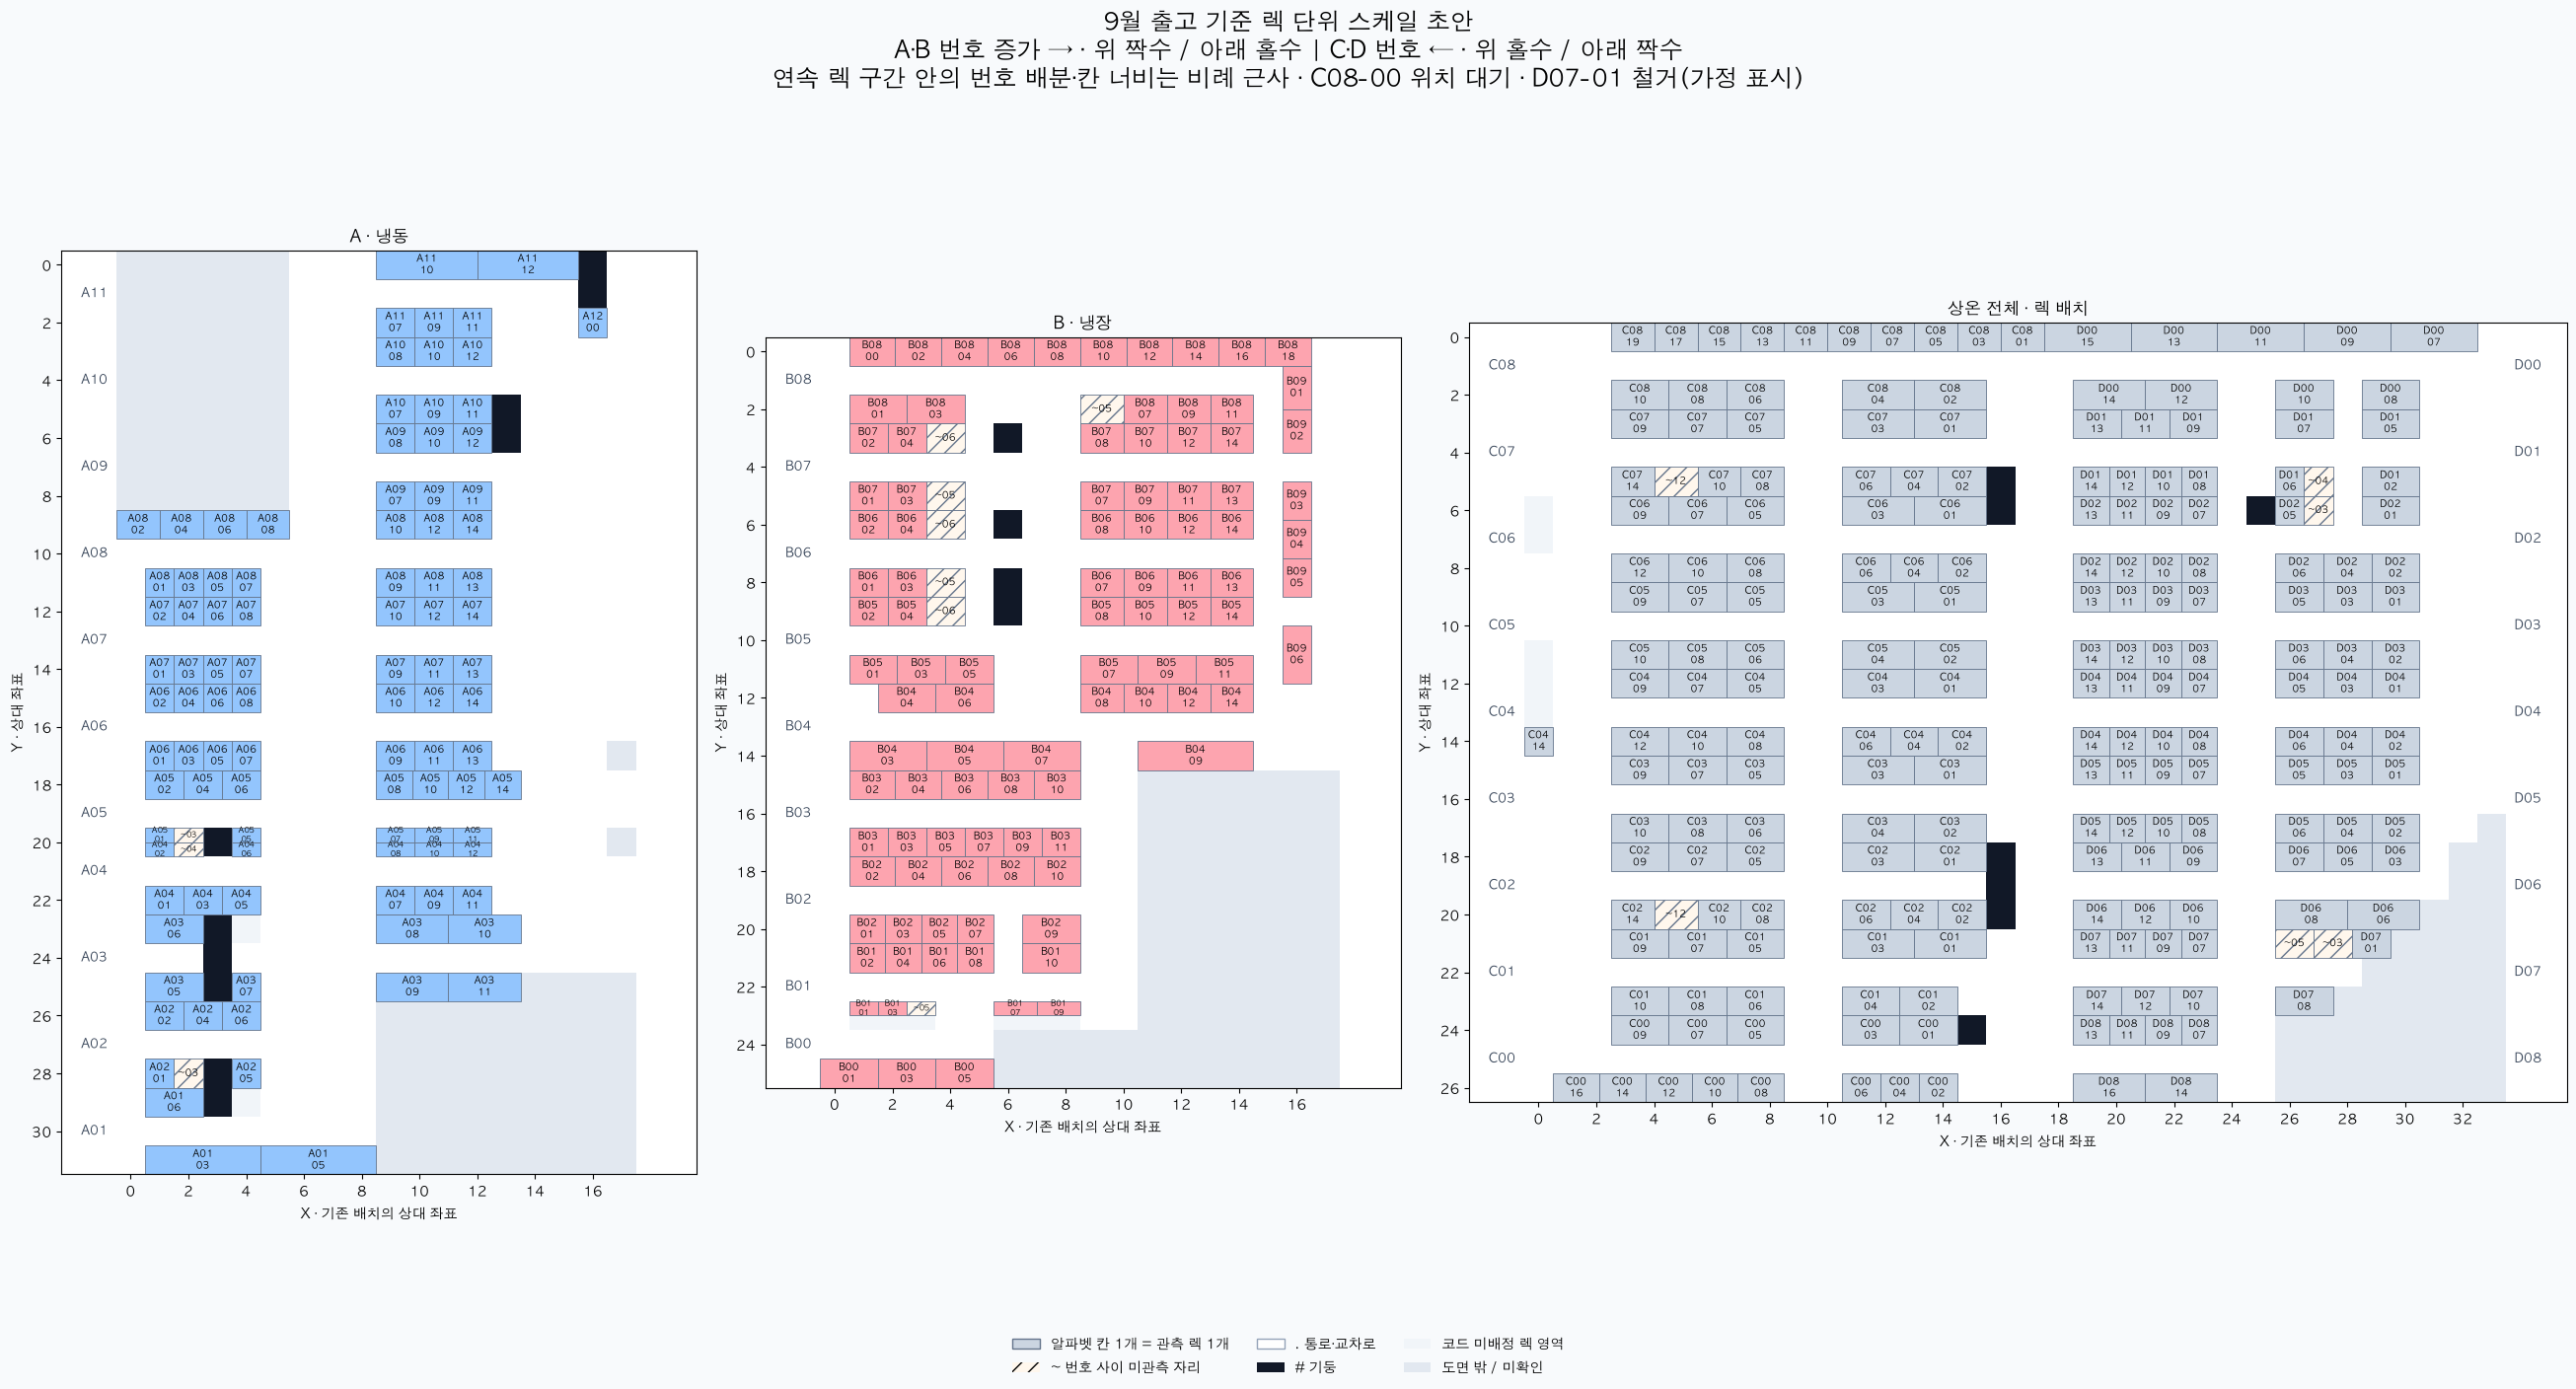

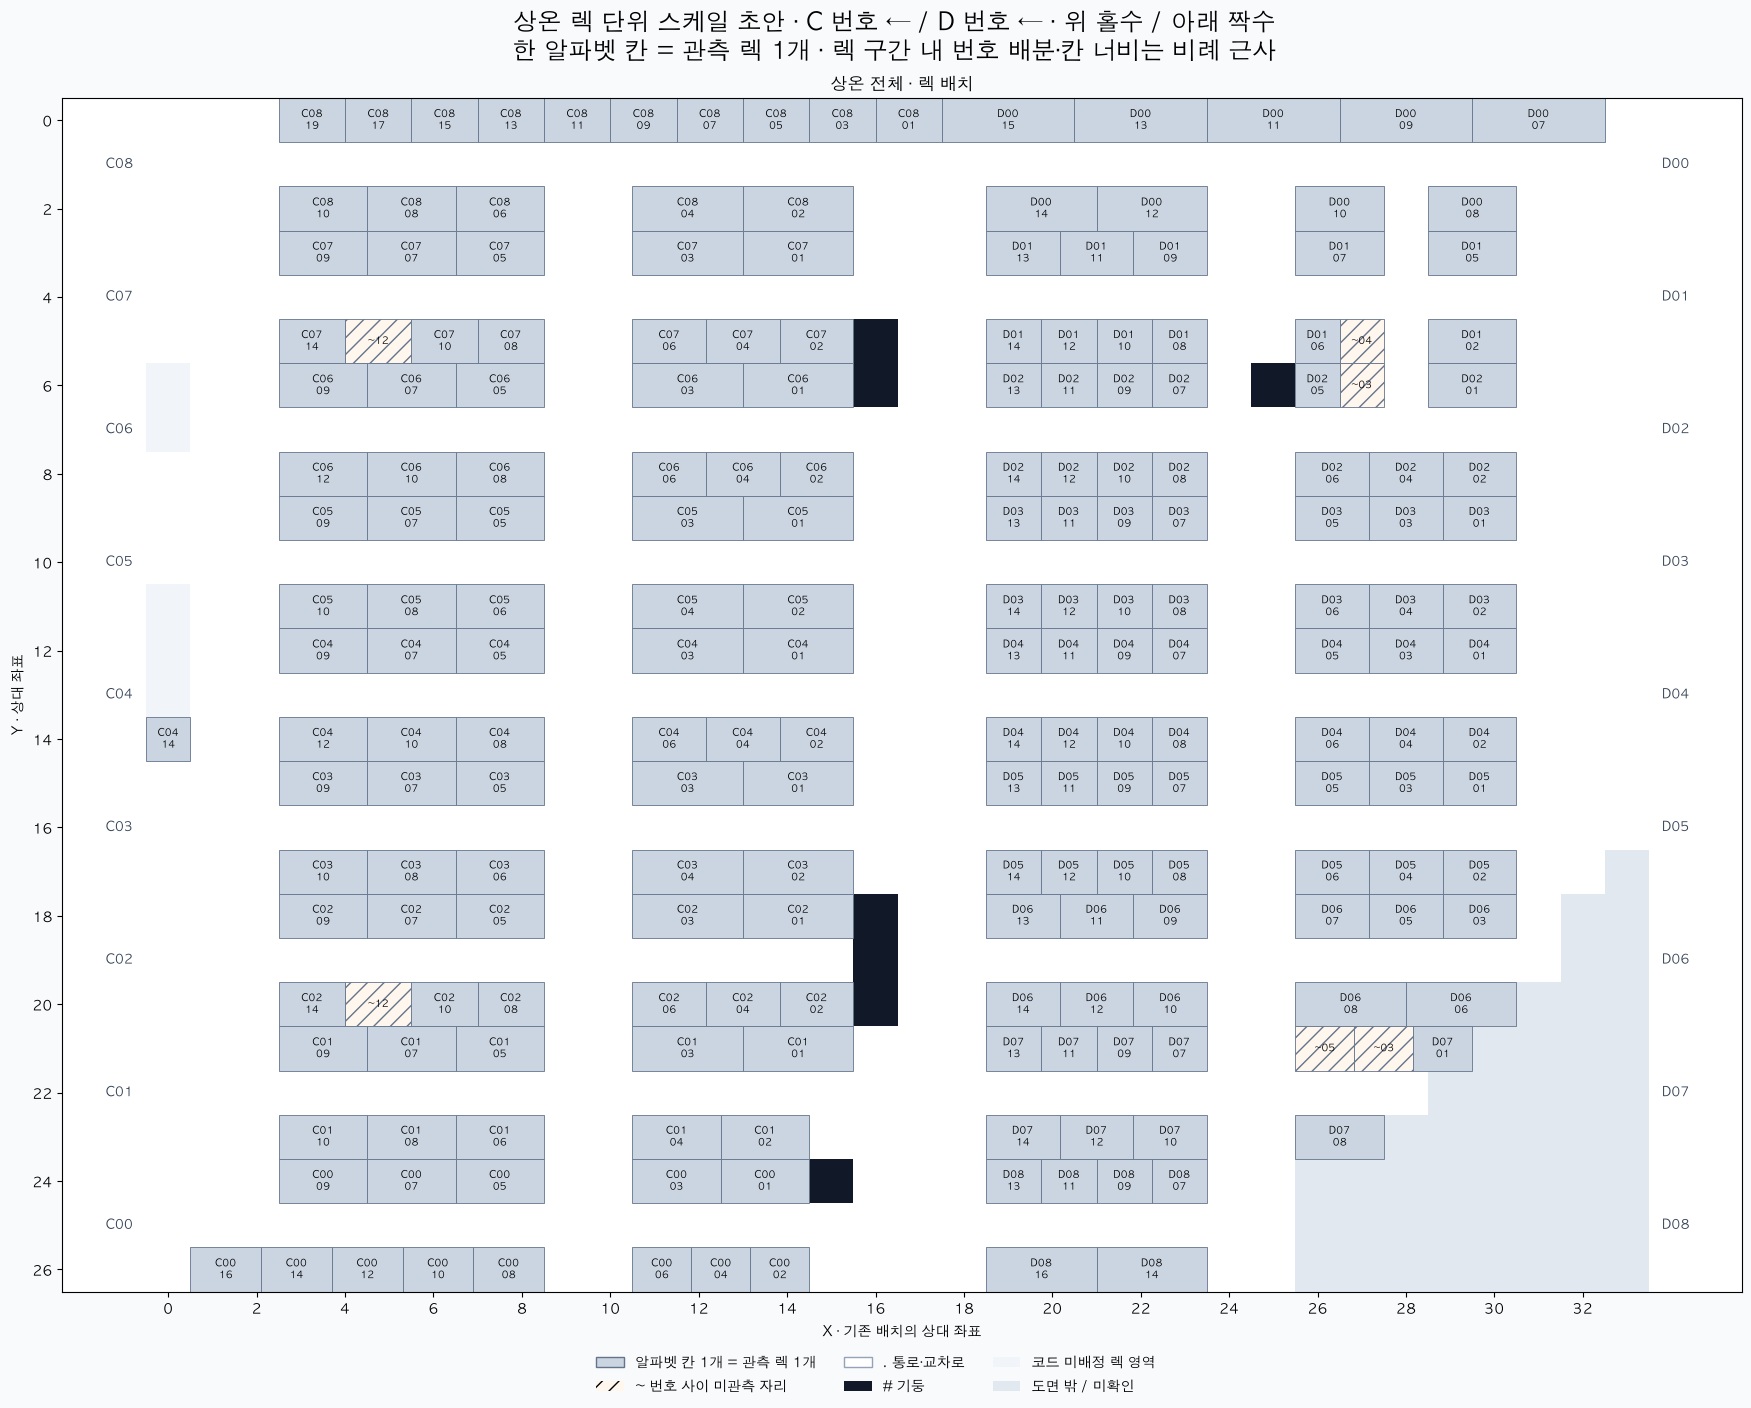

In [7]:
def draw_scaled_layout(ax, area):
    grid = layout_arrays[area]
    # 기존 렉 영역은 옅게 두고 실제 코드 칸만 그 위에 표시합니다.
    background = np.full(grid.shape, 2)
    background[grid == "."] = 0
    background[grid == "#"] = 1
    background[np.isin(grid, list("ABCDR"))] = 3
    ax.imshow(background, cmap=ListedColormap(["#ffffff", "#111827", "#e2e8f0", "#f1f5f9"]),
              vmin=0, vmax=3, interpolation="nearest")
    for cell in scaled_cells.loc[scaled_cells["area"].eq(area)].itertuples():
        color = ZONES[cell.zone]["color"] if cell.zone in {"A", "B"} else "#cbd5e1"
        if not cell.observed:
            color = "#fff7ed"
        ax.add_patch(Rectangle((cell.x, cell.y), cell.width, cell.height,
                               facecolor=color, edgecolor="#64748b", linewidth=0.6,
                               hatch=None if cell.observed else "//"))
        label = f"{cell.zone}{cell.aisle}\n{cell.rack}" if cell.observed else f"~{cell.rack}"
        ax.text(cell.x + cell.width / 2, cell.y + cell.height / 2, label,
                ha="center", va="center", fontsize=7 if cell.height >= 1 else 5.5)
    for aisle in aisle_positions.loc[aisle_positions["area"].eq(area)].itertuples():
        x = -0.8 if aisle.zone in {"A", "B", "C"} else grid.shape[1] - 0.2
        align = "right" if aisle.zone in {"A", "B", "C"} else "left"
        ax.text(x, aisle.y, f"{aisle.zone}{aisle.aisle:02}", ha=align, va="center",
                color="#334155", fontsize=9, fontweight="bold")
    ax.set(xlim=(-2.4, grid.shape[1] + 1.6), ylim=(grid.shape[0] - 0.5, -0.5),
           title=titles[area], xlabel="X · 기존 배치의 상대 좌표", ylabel="Y · 상대 좌표")
    ax.set_xticks(range(0, grid.shape[1], 2))
    ax.set_yticks(range(0, grid.shape[0], 2))


scaled_legend = [
    Patch(facecolor="#cbd5e1", edgecolor="#64748b", label="알파벳 칸 1개 = 관측 렉 1개"),
    Patch(facecolor="#fff7ed", hatch="//", label="~ 번호 사이 미관측 자리"),
    Patch(facecolor="#ffffff", edgecolor="#94a3b8", label=". 통로·교차로"),
    Patch(facecolor="#111827", label="# 기둥"),
    Patch(facecolor="#f1f5f9", label="코드 미배정 렉 영역"),
    Patch(facecolor="#e2e8f0", label="도면 밖 / 미확인"),
]
fig, axes = plt.subplots(1, 3, figsize=(26, 14), layout="constrained",
                         width_ratios=[22, 22, 38])
for ax, area in zip(axes, layout_arrays):
    draw_scaled_layout(ax, area)
fig.legend(handles=scaled_legend, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("9월 출고 기준 렉 단위 스케일 초안\n"
             "A·B 번호 증가 → · 위 짝수 / 아래 홀수 | C·D 번호 ← · 위 홀수 / 아래 짝수\n"
             "연속 렉 구간 안의 번호 배분·칸 너비는 비례 근사 · C08-00 위치 대기 · D07-01 철거(가정 표시)",
             fontsize=17)
fig.savefig(OUTPUT / "rack_scaled_layout.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(18, 14), layout="constrained")
draw_scaled_layout(ax, "C_D")
fig.legend(handles=scaled_legend, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("상온 렉 단위 스케일 초안 · C 번호 ← / D 번호 ← · 위 홀수 / 아래 짝수\n"
             "한 알파벳 칸 = 관측 렉 1개 · 렉 구간 내 번호 배분·칸 너비는 비례 근사",
             fontsize=17)
fig.savefig(OUTPUT / "ambient_scaled_layout.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. 냉동·냉장 렉 단위 확대 지도

전체 스케일 지도와 같은 배열을 사용해 A 냉동과 B 냉장을 각각 저장합니다.
A·B 모두 번호가 왼쪽→오른쪽으로 증가합니다.
A12-00, B09-01~06, B08-00(B08-02 바로 왼쪽) 예외를 포함합니다.
기존 통로·기둥을 보존하고, 렉 구간 내 번호 배분·칸 너비는 5절과 같은 비례 근사입니다.


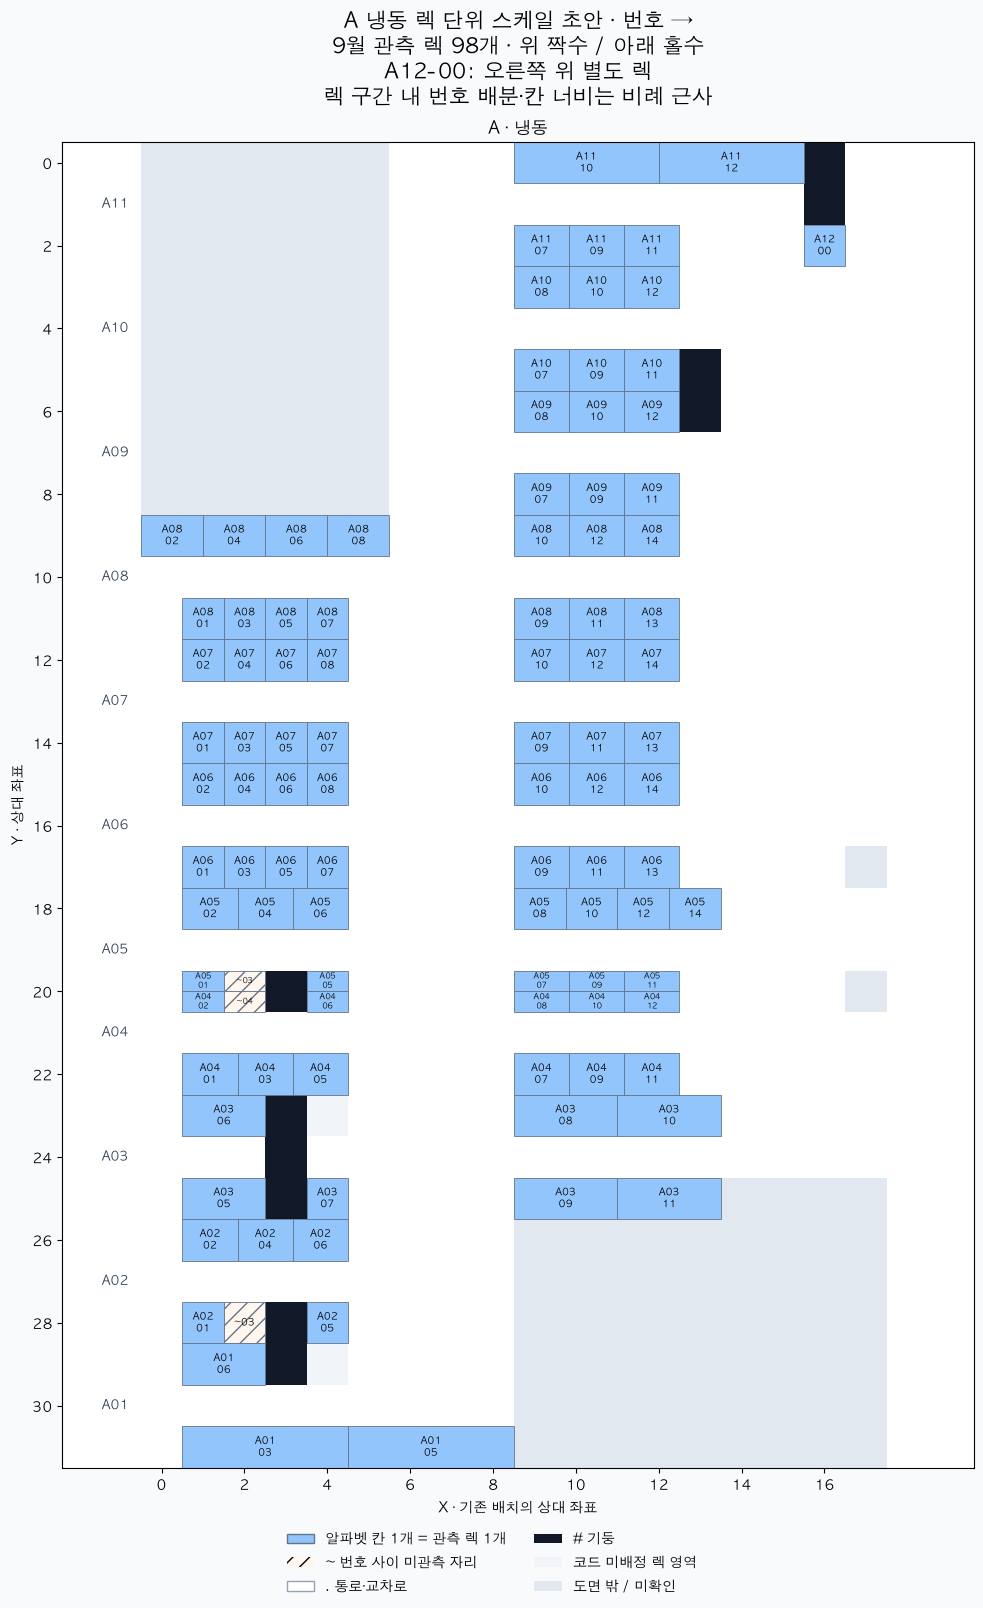

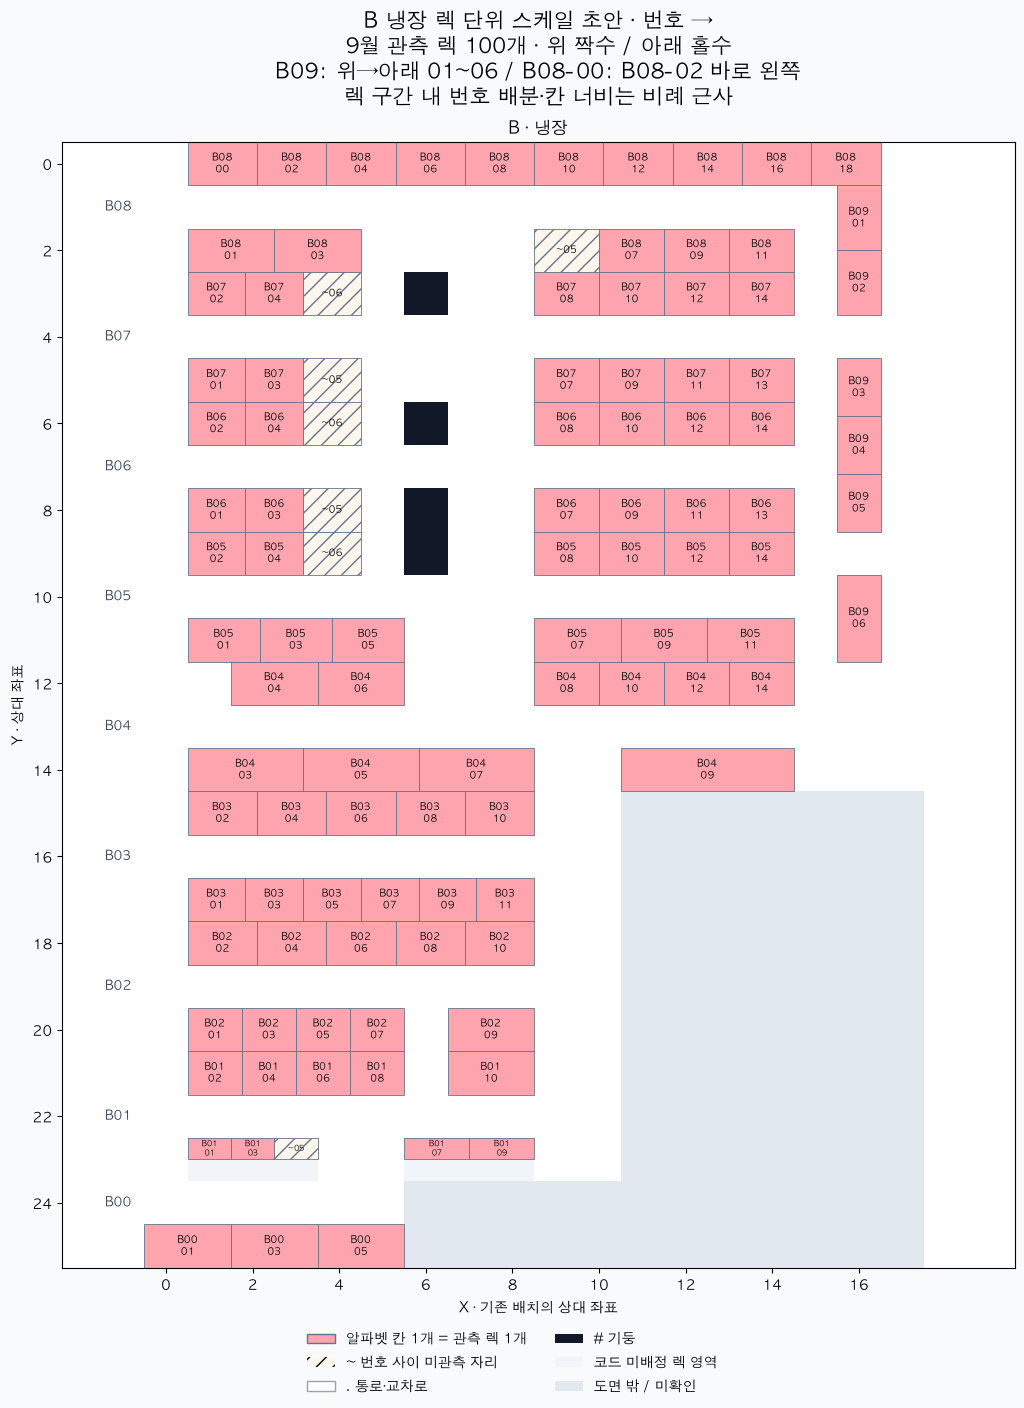

In [8]:
for area, filename, direction in [
    ("A", "frozen_scaled_layout.png", "→"),
    ("B", "refrigerated_scaled_layout.png", "→"),
]:
    fig, ax = plt.subplots(figsize=(11, 16 if area == "A" else 14), layout="constrained")
    draw_scaled_layout(ax, area)
    area_legend = [Patch(facecolor=ZONES[area]["color"], edgecolor="#64748b",
                         label="알파벳 칸 1개 = 관측 렉 1개")] + scaled_legend[1:]
    fig.legend(handles=area_legend, loc="outside lower center", ncol=2, frameon=False)
    count = int((scaled_cells["area"].eq(area) & scaled_cells["observed"]).sum())
    exception = "A12-00: 오른쪽 위 별도 렉" if area == "A" else (
        "B09: 위→아래 01~06 / B08-00: B08-02 바로 왼쪽"
    )
    fig.suptitle(f"{area} {ZONES[area]['name']} 렉 단위 스케일 초안 · 번호 {direction}\n"
                 f"9월 관측 렉 {count}개 · 위 짝수 / 아래 홀수\n"
                 f"{exception}\n렉 구간 내 번호 배분·칸 너비는 비례 근사", fontsize=15)
    fig.savefig(OUTPUT / filename, dpi=180, bbox_inches="tight")
    plt.show()
